# 07 - Series en el tiempo: CropX y comparativa con la telemetría fija

Series en el tiempo de CropX y comparativa por tipo de variable (fija continua, CropX discontinua), con
líneas verticales en los límites de cada etapa (incluye Descanso). Los estadísticos, correlación, varianza,
comparación de fincas y alarmas de CropX están en los notebooks 02 a 06.
Rutas y grupos de variables en `config.py` (`RUTAS_CROPX`, `COL_TIEMPO_CROPX`, `GRUPOS_CROPX`, `GRUPOS_COMPARATIVA`).

> Ejecutar las celdas en orden. Usa `config.py` y `funciones_comunes.py` (misma carpeta).

In [1]:
# =============================================================================
# LIBRERÍAS
# =============================================================================
import re
import warnings
from dataclasses import dataclass
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.gridspec import GridSpec
import seaborn as sns
import ipywidgets as widgets
from scipy import stats
from IPython.display import display, Markdown

warnings.filterwarnings("ignore", category=FutureWarning)
# Gradientes de color sobre filas sin datos válidos (sensor descartado): aviso inofensivo de pandas
warnings.filterwarnings("ignore", message="All-NaN slice encountered")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)

In [2]:
# =============================================================================
# CONFIGURACION Y FUNCIONES COMUNES (editar config.py y reiniciar el kernel)
# =============================================================================
from config import *
from funciones_comunes import (_limites_rango, obtener_rangos, periodo_finca, filtrar_etapa, columnas_analisis,
                               cargar_finca, cargar_bd_fija, cargar_cropx, cargar_bd_cropx,
                               mostrar_sin_datos, contar_por_banda, _ajustar_slider)

In [3]:
# Telemetría fija y CropX de todas las fincas, recortadas al periodo de sus etapas (incluye Descanso)
BD_FIJA_FILTERED = cargar_bd_fija()
BD_CROPX = cargar_bd_cropx()
BASES = {NOMBRE_BD_FIJA: BD_FIJA_FILTERED, NOMBRE_BD_CROPX: BD_CROPX}


Cargando datos de la finca: La_Orquidea
Se eliminaron 0 filas con valores NaN en la columna 'timestamp' y 0 filas con índice NaN.
Datos cargados para La_Orquidea: 17447 filas y 43 columnas.

Cargando datos de la finca: Venecia
Se eliminaron 0 filas con valores NaN en la columna 'timestamp' y 0 filas con índice NaN.
Datos cargados para Venecia: 17199 filas y 43 columnas.

Cargando datos de la finca: Puerto_Arturo
Se eliminaron 0 filas con valores NaN en la columna 'timestamp' y 0 filas con índice NaN.
Datos cargados para Puerto_Arturo: 17064 filas y 43 columnas.
La_Orquidea: fechas en reloj de 12 h sin AM/PM -> 8733 registros pasados a la tarde según el orden del archivo.
La_Orquidea: 17449 registros CropX, 2025-10-21 10:00:00 a 2026-10-19 22:30:00
Venecia: fechas en reloj de 12 h sin AM/PM -> 8736 registros pasados a la tarde según el orden del archivo.
Venecia: 17450 registros CropX, 2025-10-21 11:00:00 a 2026-10-19 23:30:00
Puerto_Arturo: fechas en reloj de 12 h sin AM/PM -> 3360 re

# CropX en el tiempo
`BD_CROPX` se carga arriba con `cargar_bd_cropx()` (en `funciones_comunes.py`).

In [4]:
# =============================================================================
# 3. BASE DE DATOS CROPX: carga, estadísticos y gráficas en el tiempo
# =============================================================================

def color_profundidad(columna: str) -> str:
    """Color según la profundidad escrita en el nombre de la columna (20, 40/41, 60/66 cm).

    Args:
        columna (str): Nombre de la columna (p. ej. "Moisture 41" o "top_ph_20cm").

    Returns:
        str: Color de matplotlib; gris oscuro si el nombre no tiene profundidad (variables de aire).
    """
    numero = re.search(r"\d+", columna)
    return COLORES_PROFUNDIDAD.get(numero.group(), "0.3") if numero else "0.3"


def dibujar_serie(ax: plt.Axes, serie: pd.Series, etiqueta: str, color: str,
                  estilo: str = "-", ventana_horas: int = 24, crudo: bool = True) -> None:
    """Dibuja el promedio horario (línea tenue) y su promedio móvil (línea gruesa).

    Args:
        ax (plt.Axes): Eje donde dibujar.
        serie (pd.Series): Variable con índice temporal.
        etiqueta (str): Texto de la leyenda.
        color (str): Color de la serie.
        estilo (str): Estilo de línea del promedio móvil ("-" continua, "--" discontinua).
        ventana_horas (int): Horas del promedio móvil.
        crudo (bool): True para dibujar también el promedio horario tenue.

    Returns:
        None
    """
    horaria = serie.resample("1h").mean()                 # los huecos sin datos quedan en blanco
    if horaria.notna().sum() == 0:
        return
    if crudo:
        ax.plot(horaria.index, horaria, color=color, alpha=0.22, linewidth=0.6)
    movil = horaria.rolling(ventana_horas, min_periods=ventana_horas).mean()   # solo ventanas completas
    ax.plot(movil.index, movil, color=color, linestyle=estilo, linewidth=1.7, label=etiqueta)


def cerrar_panel(ax: plt.Axes, fontsize: float = 9) -> None:
    """Pone la leyenda del panel o, si no se dibujó ninguna serie, el aviso "Sin datos".

    Args:
        ax (plt.Axes): Eje del panel.
        fontsize (float): Tamaño de letra de la leyenda.

    Returns:
        None
    """
    if ax.get_legend_handles_labels()[0]:
        ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=fontsize)
    else:
        ax.text(0.5, 0.5, "Sin datos en este periodo", ha="center", va="center",
                transform=ax.transAxes, color="0.4")


def marcar_etapas(ax: plt.Axes, finca: str, etiquetas: bool = False) -> None:
    """Dibuja una línea vertical en el inicio y fin de cada etapa de la finca.

    Args:
        ax (plt.Axes): Eje donde dibujar.
        finca (str): Nombre de la finca.
        etiquetas (bool): True para escribir el nombre de cada etapa encima del eje.

    Returns:
        None
    """
    for i, (etapa, (inicio, fin)) in enumerate(obtener_rangos(FINCAS_POR_NOMBRE[finca]).items()):
        t_ini, t_fin = _limites_rango(inicio, fin)
        ax.axvline(t_ini, color="0.2", linestyle="--", linewidth=0.9)
        ax.axvline(t_fin, color="0.2", linestyle="--", linewidth=0.9)
        if etiquetas:                                      # altura alterna: etapas cortas no se montan
            ax.text(t_ini + (t_fin - t_ini) / 2, 1.02 + 0.07 * (i % 2), etapa, ha="center",
                    transform=ax.get_xaxis_transform(), fontsize=9, fontweight="bold")


def formato_fechas(ax: plt.Axes) -> None:
    """Eje x con fechas espaciadas (máximo ~12 marcas) en formato dd/mm/aa.

    Args:
        ax (plt.Axes): Eje al que se le da formato.

    Returns:
        None
    """
    ax.xaxis.set_major_locator(mdates.AutoDateLocator(minticks=6, maxticks=12))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m/%y"))
    ax.tick_params(axis="x", rotation=45)
    ax.grid(alpha=0.3)


def estadisticos_cropx(finca: str) -> None:
    """Tabla de estadísticos descriptivos de las variables CropX de una finca.

    Args:
        finca (str): Nombre de la finca (clave de BD_CROPX).

    Returns:
        None: Muestra la tabla.
    """
    display(Markdown(f"### Estadísticos CropX - {finca}"))
    if finca not in BD_CROPX or BD_CROPX[finca].empty:
        display(Markdown("_Sin datos CropX para esta finca._"))
        return
    tabla = BD_CROPX[finca].describe().T
    tabla.insert(1, "% faltantes", 100 * (1 - tabla["count"] / len(BD_CROPX[finca])))
    display(tabla.style.bar(subset=["mean"], color="lightblue")
            .background_gradient(subset=["std", "50%", "max"], cmap="YlGnBu")
            .format(precision=2, na_rep="-"))


def graficar_cropx(finca: str, ventana_horas: int = 24) -> None:
    """Gráfica en el tiempo de CropX: un panel por tipo de variable, comparando profundidades.

    Args:
        finca (str): Nombre de la finca (clave de BD_CROPX).
        ventana_horas (int): Horas del promedio móvil.

    Returns:
        None: Muestra la figura.
    """
    if finca not in BD_CROPX:
        mostrar_sin_datos(f"CropX - {finca}", "La finca no tiene archivo CropX")
        return
    df = BD_CROPX[finca]
    fig, axes = plt.subplots(len(GRUPOS_CROPX), 1, figsize=(14, 3.3 * len(GRUPOS_CROPX)), sharex=True)

    for i, (ax, (grupo, columnas)) in enumerate(zip(axes, GRUPOS_CROPX.items())):
        for columna in columnas:
            if columna in df.columns:
                dibujar_serie(ax, df[columna], columna, color_profundidad(columna),
                              ventana_horas=ventana_horas)
        marcar_etapas(ax, finca, etiquetas=(i == 0))
        formato_fechas(ax)
        ax.set_ylabel(grupo)
        cerrar_panel(ax, 9)

    axes[0].set_xlim(*periodo_finca(finca))                # todo el periodo de las etapas (incluye Descanso)
    fig.suptitle(f"CropX - {finca}: promedio horario y promedio móvil de {ventana_horas} h", y=1.0)
    plt.tight_layout()
    plt.show()

### Estadísticos CropX - La_Orquidea

,count,% faltantes,mean,std,min,25%,50%,75%,max
Moisture 20,17449.00,0.00,37.66,10.56,5.04,27.52,44.16,45.03,46.49
Moisture 41,17449.00,0.00,36.30,9.92,7.70,33.72,40.96,42.11,45.41
Moisture 66,17449.00,0.00,43.79,12.92,7.99,46.76,48.80,50.13,50.71
Temperature 20,17449.00,0.00,22.92,1.18,20.87,22.00,22.62,23.87,27.12
Temperature 41,17449.00,0.00,23.00,0.99,21.37,22.12,22.75,23.87,25.00
ECpw 20,17449.00,0.00,0.26,0.09,0.00,0.22,0.24,0.30,6.21
ECpw 41,17448.00,0.01,0.22,0.09,0.00,0.19,0.21,0.23,7.09
ECpw 66,17447.00,0.01,0.17,0.07,0.00,0.14,0.15,0.15,0.99


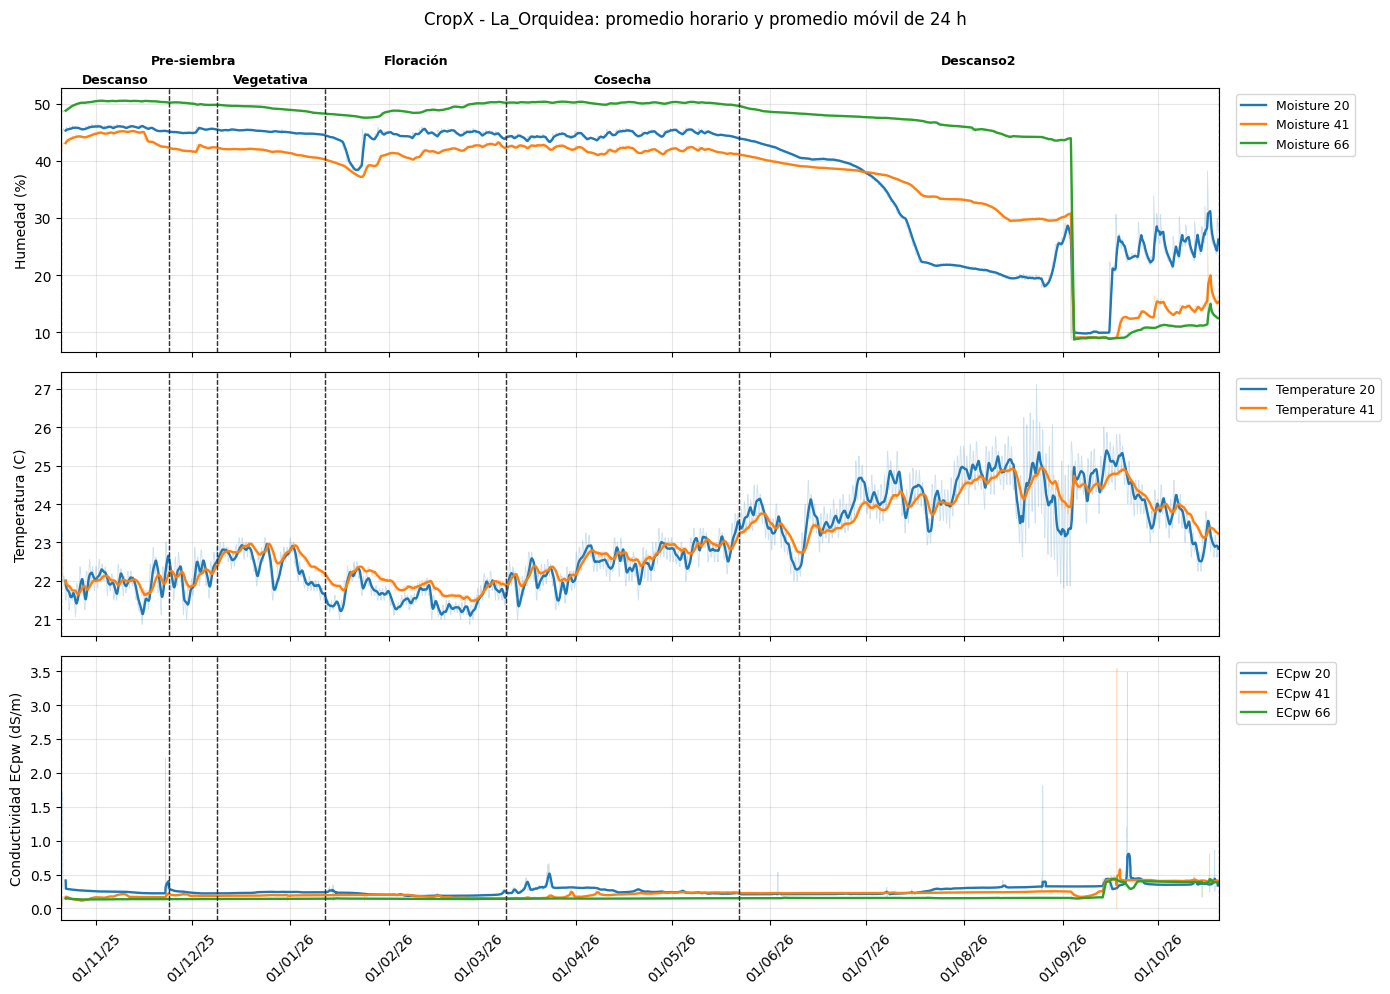

In [5]:
estadisticos_cropx("La_Orquidea")
graficar_cropx("La_Orquidea")

### Estadísticos CropX - Venecia

,count,% faltantes,mean,std,min,25%,50%,75%,max
Moisture 20,17450.00,0.00,31.90,4.22,3.61,30.87,31.74,34.66,38.97
Moisture 41,17450.00,0.00,34.41,2.41,4.08,34.02,34.79,35.45,39.65
Moisture 66,17450.00,0.00,41.67,3.97,5.44,41.75,42.84,43.55,46.78
Temperature 20,17450.00,0.00,21.32,0.75,19.12,20.87,21.37,21.87,23.25
Temperature 41,17450.00,0.00,21.57,0.56,20.25,21.25,21.75,22.00,24.00
ECpw 20,17450.00,0.00,1.60,0.92,0.00,0.66,1.38,2.54,7.61
ECpw 41,17450.00,0.00,1.59,0.45,0.61,1.14,1.76,1.99,7.46
ECpw 66,17450.00,0.00,0.83,0.17,0.29,0.74,0.87,0.95,5.81


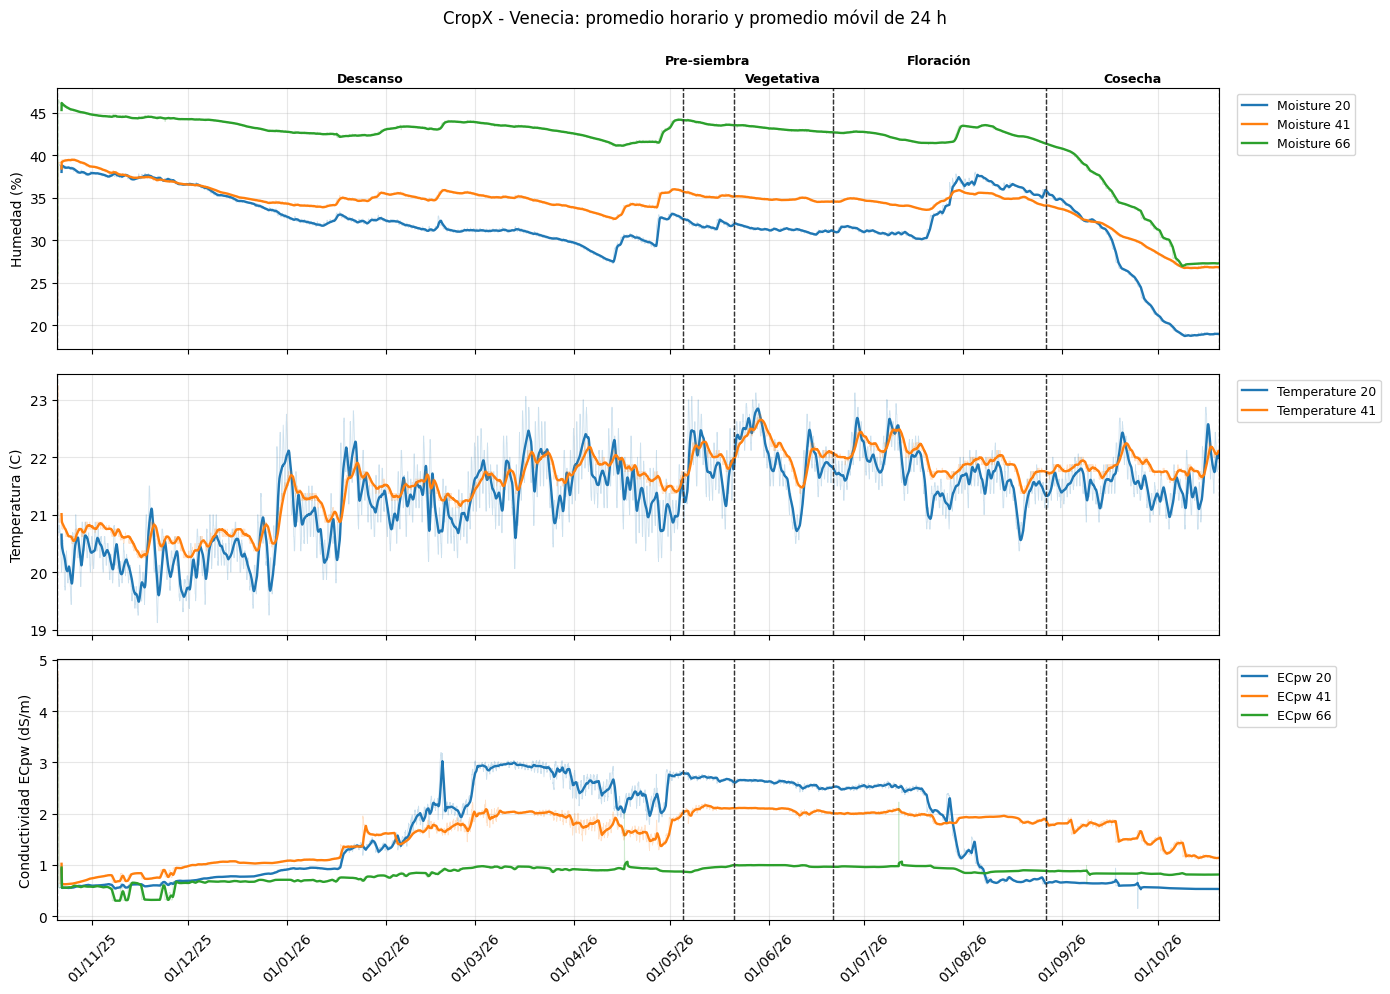

In [6]:
estadisticos_cropx("Venecia")
graficar_cropx("Venecia")

### Estadísticos CropX - Puerto_Arturo

,count,% faltantes,mean,std,min,25%,50%,75%,max
Moisture 20,6697.00,0.00,13.54,6.97,4.40,9.05,9.71,19.38,31.30
Moisture 41,6697.00,0.00,16.89,5.60,4.62,13.67,16.66,21.61,35.55
Moisture 66,6697.00,0.00,26.01,8.32,6.36,19.58,27.96,32.46,40.59
Temperature 20,6697.00,0.00,22.32,2.62,14.75,21.37,22.25,23.37,36.00
Temperature 41,6697.00,0.00,20.47,6.64,0.12,21.62,22.12,23.25,36.25
ECpw 20,6696.00,0.01,0.51,0.10,0.00,0.51,0.52,0.54,6.01
ECpw 41,6696.00,0.01,0.48,0.12,0.00,0.45,0.50,0.54,7.18
ECpw 66,6696.00,0.01,0.35,0.07,0.03,0.32,0.35,0.39,1.65


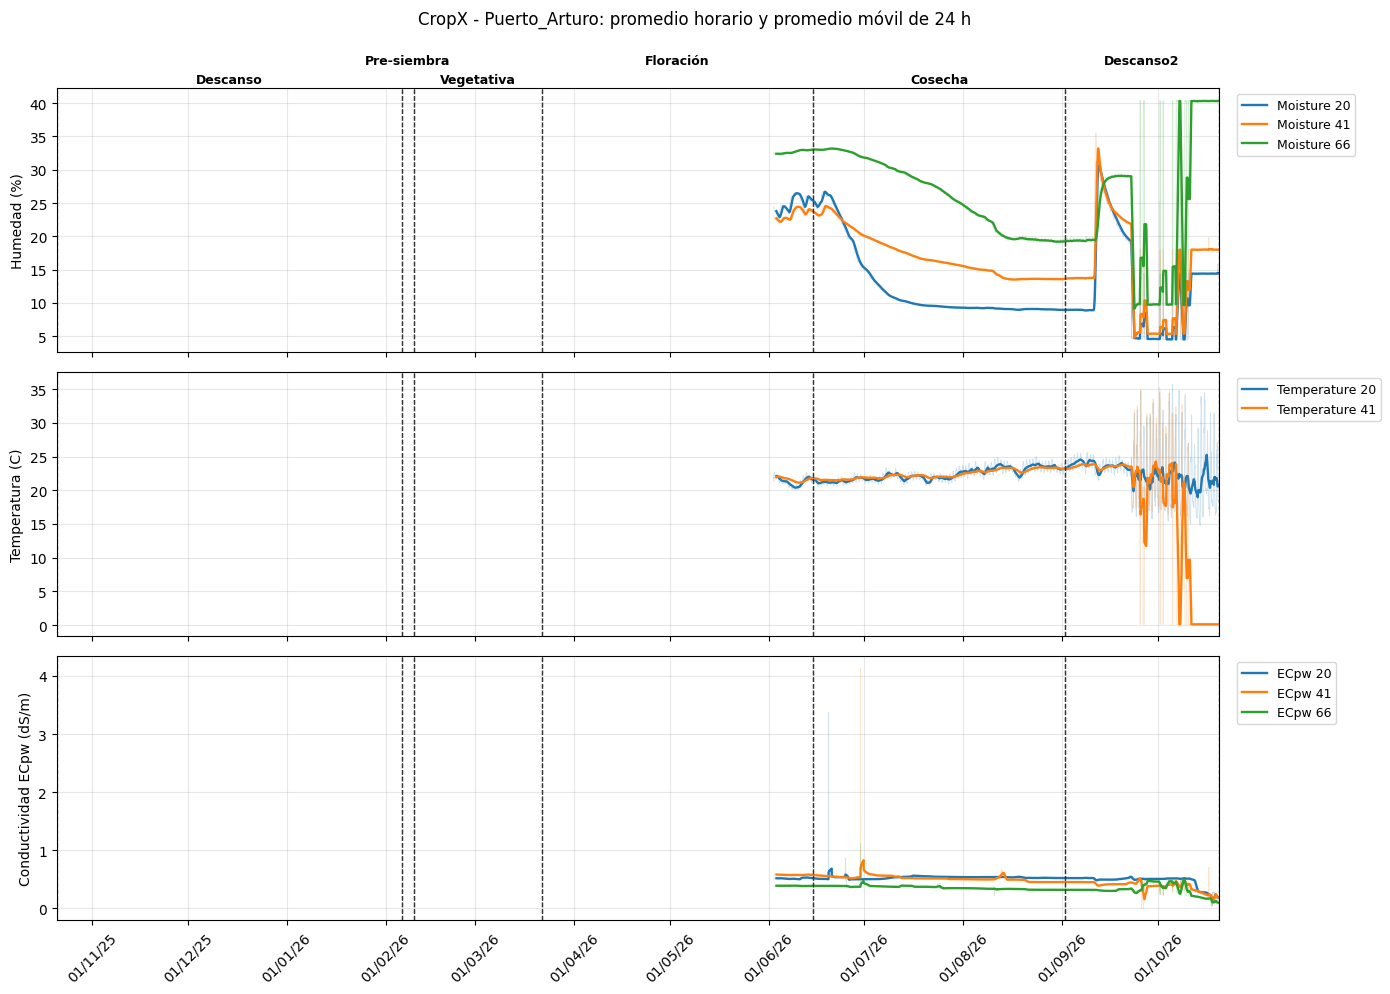

In [7]:
estadisticos_cropx("Puerto_Arturo")
graficar_cropx("Puerto_Arturo")

## Comparativa en el tiempo: telemetría fija + CropX

In [8]:
# =============================================================================
# 4. COMPARATIVA EN EL TIEMPO POR TIPO DE VARIABLE (telemetría fija + CropX)
#    Requiere la celda de CropX (BD_CROPX, dibujar_serie, marcar_etapas, formato_fechas, color_profundidad)
# =============================================================================
def graficar_comparativa(finca: str, grupos: list[str] | None = None,
                         ventana_horas: int = 24, crudo: bool = False) -> None:
    """Gráfica en el tiempo de una finca: un panel por tipo de variable, fija (continua) y CropX (discontinua).

    Args:
        finca (str): Nombre de la finca, p. ej. "La_Orquidea".
        grupos (list[str] | None): Claves de GRUPOS_COMPARATIVA a graficar; None para todas.
        ventana_horas (int): Horas del promedio móvil.
        crudo (bool): True para dibujar también el promedio horario tenue.

    Returns:
        None: Muestra la figura.
    """
    fija = BD_FIJA_FILTERED.get(finca, pd.DataFrame())     # vacío si la finca no tiene telemetría
    cropx = BD_CROPX.get(finca, pd.DataFrame())            # vacío si la finca no tiene CropX
    grupos = grupos or list(GRUPOS_COMPARATIVA)

    fig, axes = plt.subplots(len(grupos), 1, figsize=(14, 3.3 * len(grupos)), sharex=True, squeeze=False)
    axes = axes.flatten()

    for i, (ax, grupo) in enumerate(zip(axes, grupos)):
        for columna in GRUPOS_COMPARATIVA[grupo]["fija"]:
            if columna in fija.columns:
                dibujar_serie(ax, fija[columna], f"Fija - {columna}", color_profundidad(columna),
                              "-", ventana_horas, crudo)
        for columna in GRUPOS_COMPARATIVA[grupo]["cropx"]:
            if columna in cropx.columns:
                dibujar_serie(ax, cropx[columna], f"CropX - {columna}", color_profundidad(columna),
                              "--", ventana_horas, crudo)

        marcar_etapas(ax, finca, etiquetas=(i == 0))
        formato_fechas(ax)
        ax.set_ylabel(grupo)
        cerrar_panel(ax, 8.5)

    axes[0].set_xlim(*periodo_finca(finca))                # todo el periodo de las etapas (incluye Descanso)
    fig.suptitle(f"{finca}: comparativa por tipo de variable (promedio móvil de {ventana_horas} h)", y=1.0)
    plt.tight_layout()
    plt.show()

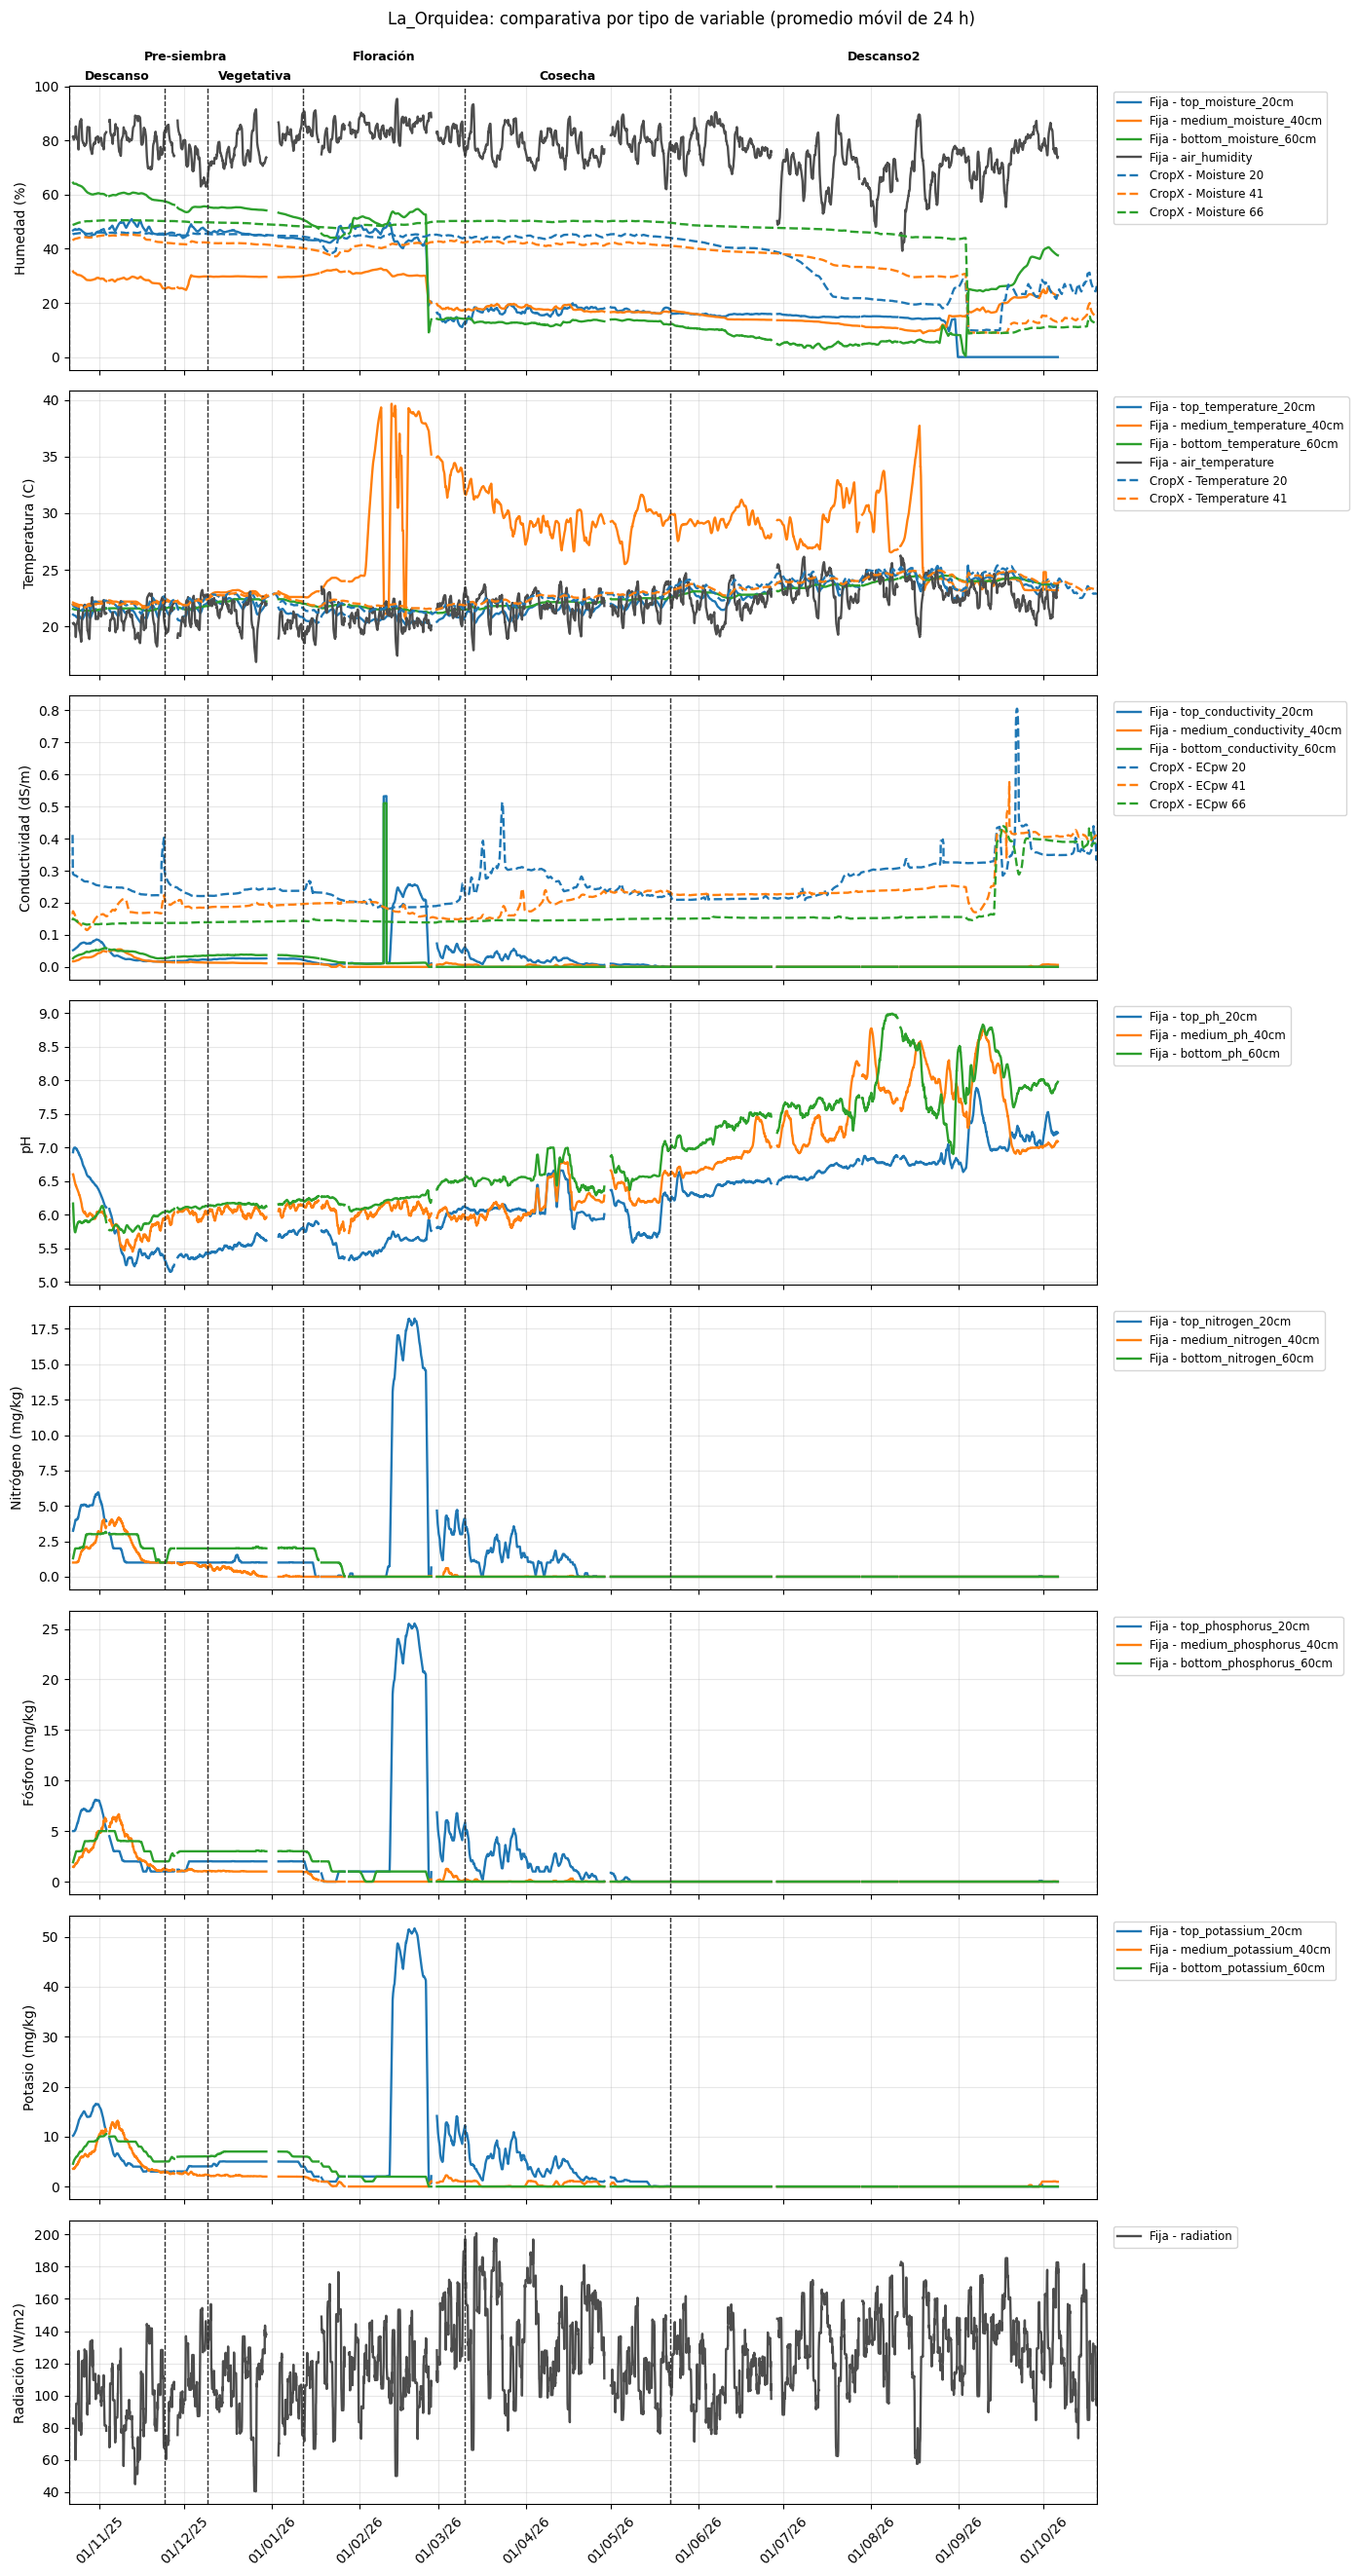

In [9]:
graficar_comparativa("La_Orquidea")

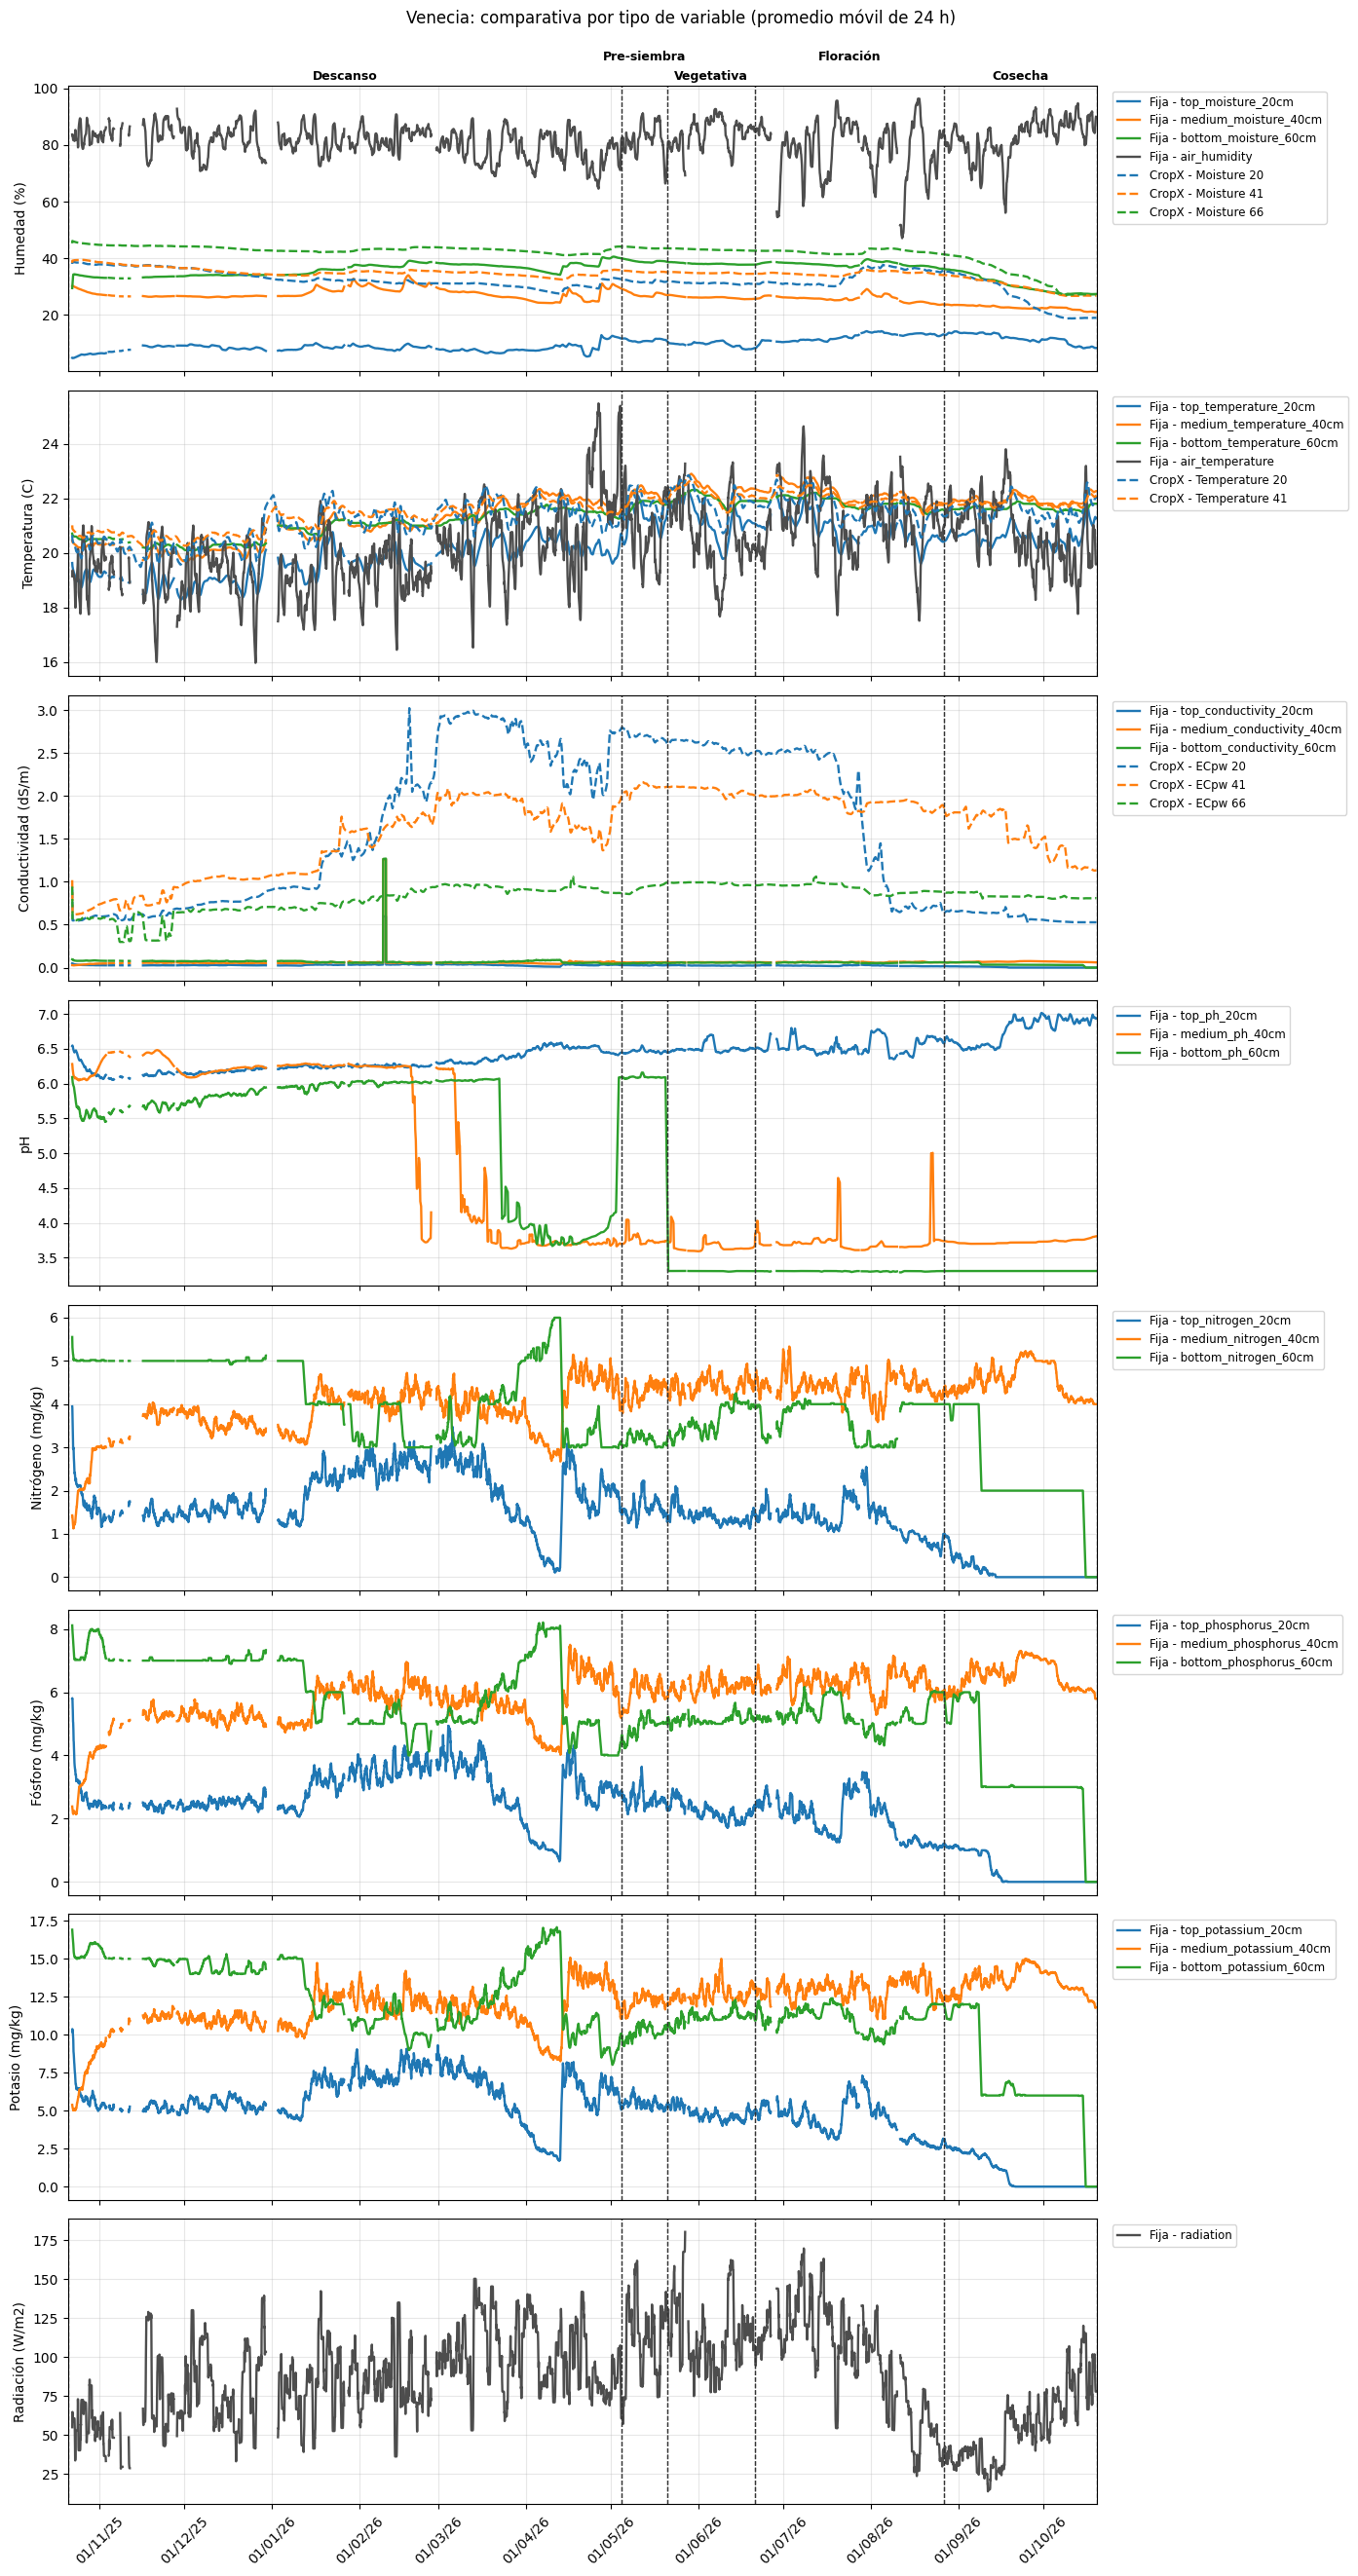

In [10]:
graficar_comparativa("Venecia")

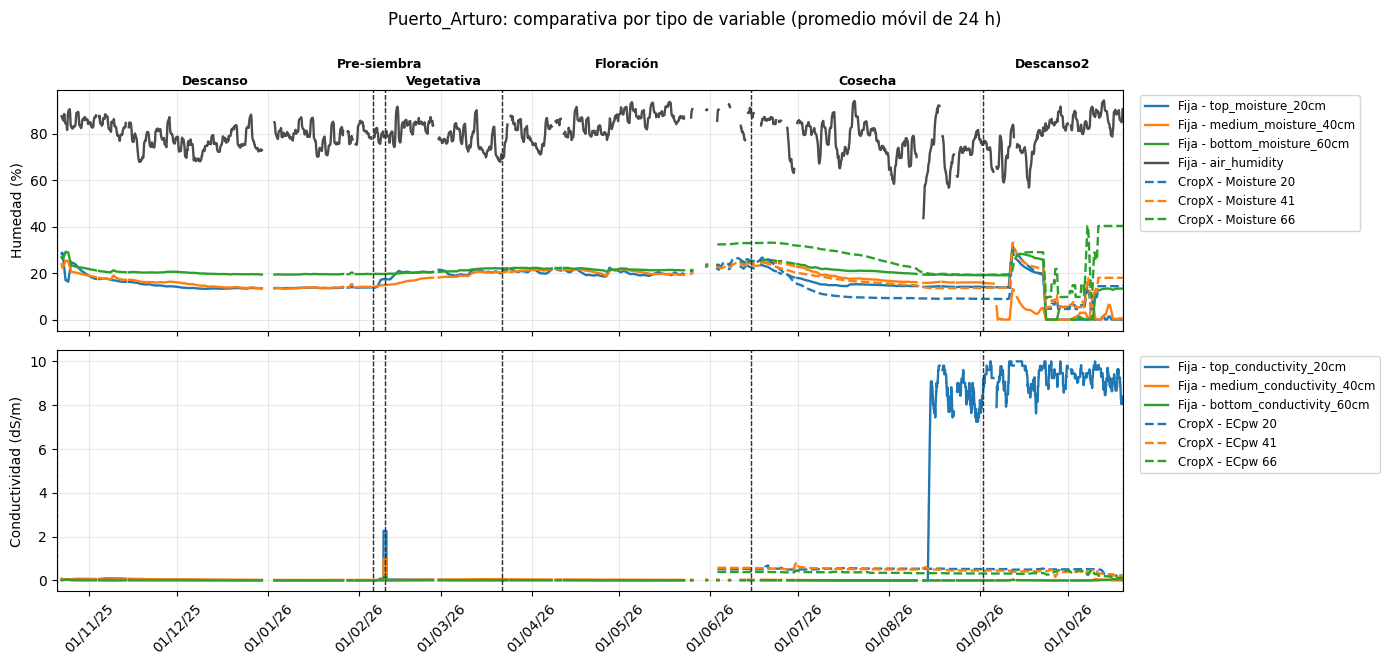

In [11]:
graficar_comparativa("Puerto_Arturo", grupos=["Humedad (%)", "Conductividad (dS/m)"])